<a href="https://colab.research.google.com/github/tattoosbyhannah-cmyk/superkart-model-deployment/blob/main/FINAL_of_Full_Code_SuperKart_Model_Deployment_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Problem Statement**

## Business Context

A sales forecast is a prediction of future sales revenue based on historical data, industry trends, and the status of the current sales pipeline. Businesses use the sales forecast to estimate weekly, monthly, quarterly, and annual sales totals. A company needs to make an accurate sales forecast as it adds value across an organization and helps the different verticals to chalk out their future course of action.

Forecasting helps an organization plan its sales operations by region and provides valuable insights to the supply chain team regarding the procurement of goods and materials. An accurate sales forecast process has many benefits which include improved decision-making about the future and reduction of sales pipeline and forecast risks. Moreover, it helps to reduce the time spent in planning territory coverage and establish benchmarks that can be used to assess trends in the future.

## Objective

SuperKart is a retail chain operating supermarkets and food marts across various tier cities, offering a wide range of products. To optimize its inventory management and make informed decisions around regional sales strategies, SuperKart wants to accurately forecast the sales revenue of its outlets for the upcoming quarter.

To operationalize these insights at scale, the company has partnered with a data science firm—not just to build a predictive model based on historical sales data, but to develop and deploy a robust forecasting solution that can be integrated into SuperKart’s decision-making systems and used across its network of stores.

## Data Description

The data contains the different attributes of the various products and stores.The detailed data dictionary is given below.

- **Product_Id** - unique identifier of each product, each identifier having two letters at the beginning followed by a number.
- **Product_Weight** - weight of each product
- **Product_Sugar_Content** - sugar content of each product like low sugar, regular and no sugar
- **Product_Allocated_Area** - ratio of the allocated display area of each product to the total display area of all the products in a store
- **Product_Type** - broad category for each product like meat, snack foods, hard drinks, dairy, canned, soft drinks, health and hygiene, baking goods, bread, breakfast, frozen foods, fruits and vegetables, household, seafood, starchy foods, others
- **Product_MRP** - maximum retail price of each product
- **Store_Id** - unique identifier of each store
- **Store_Establishment_Year** - year in which the store was established
- **Store_Size** - size of the store depending on sq. feet like high, medium and low
- **Store_Location_City_Type** - type of city in which the store is located like Tier 1, Tier 2 and Tier 3. Tier 1 consists of cities where the standard of living is comparatively higher than its Tier 2 and Tier 3 counterparts.
- **Store_Type** - type of store depending on the products that are being sold there like Departmental Store, Supermarket Type 1, Supermarket Type 2 and Food Mart
- **Product_Store_Sales_Total** - total revenue generated by the sale of that particular product in that particular store


# **Installing and Importing the necessary libraries**

In [1]:
# Installing the libraries with the specified versions
# NOTE: scikit-learn and xgboost versions here MUST match the versions in backend_files/requirements.txt,
# otherwise the serialized model may fail to load (or predict incorrectly) inside the Docker container.
!pip install pandas==2.2.2 numpy==2.0.2 scikit-learn==1.6.1 xgboost==2.1.4 joblib==1.4.2 matplotlib seaborn requests PyGithub==2.6.1 -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.4/4.4 MB 20.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  error: subprocess-exited-with-error
  
  × Preparing metadata (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (pyproject.toml) ... error
error: metadata-generation-failed

× Encountered error while generating package metadata.
╰─> See above for output.

note: This is an issue with the package mentioned above, not pip.
hint: See above for details.


**Note:**

- After running the above cell, kindly restart the notebook kernel (for Jupyter Notebook) or runtime (for Google Colab) and run all cells sequentially from the next cell.

- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in this notebook.

In [2]:
!pip install PyGithub -q

import warnings
warnings.filterwarnings("ignore")

# Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd

# For splitting the dataset
from sklearn.model_selection import train_test_split

# Libaries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Removes the limit for the number of displayed columns
pd.set_option("display.max_columns", None)
# Sets the limit for the number of displayed rows
pd.set_option("display.max_rows", 100)


# Libraries different ensemble classifiers
from sklearn.ensemble import (
    BaggingRegressor,
    RandomForestRegressor,
    AdaBoostRegressor,
    GradientBoostingRegressor,
)
from xgboost import XGBRegressor
from sklearn.tree import DecisionTreeRegressor

# Libraries to get different metric scores
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    mean_absolute_percentage_error
)

# To create the pipeline
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline,Pipeline

# To tune different models and standardize
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler,OneHotEncoder

# To serialize the model
import joblib

# os related functionalities
import os

# API request
import requests

# for pushing deployment files to GitHub
from github import Github

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.6/455.6 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 32.2 MB/s eta 0:00:00


# **Loading the dataset**

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# Load the dataset from a CSV file into a Pandas DataFrame from Google Drive
kart = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/model deoployment/SuperKart.csv')

In [5]:
# Create a copy of the dataframe to avoid changing the original data
dataset = kart.copy()

# **Data Overview**

In [6]:
# Display the first five rows of the dataset
dataset.head()

,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,2009,Medium,Tier 2,Supermarket Type2,2842.40
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,1999,Medium,Tier 1,Departmental Store,4830.02
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,1987,High,Tier 2,Supermarket Type1,4130.16
3,FD8233,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,1987,High,Tier 2,Supermarket Type1,4132.18
4,NC1180,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,1998,Small,Tier 3,Food Mart,2279.36


In [7]:
# Display the number of rows and columns in the dataset
dataset.shape

(8763, 12)

In [8]:
# Display the column names of the dataset
dataset.columns

Index(['Product_Id', 'Product_Weight', 'Product_Sugar_Content',
       'Product_Allocated_Area', 'Product_Type', 'Product_MRP', 'Store_Id',
       'Store_Establishment_Year', 'Store_Size', 'Store_Location_City_Type',
       'Store_Type', 'Product_Store_Sales_Total'],
      dtype='object')

In [9]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8763 entries, 0 to 8762
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Product_Id                 8763 non-null   object 
 1   Product_Weight             8763 non-null   float64
 2   Product_Sugar_Content      8763 non-null   object 
 3   Product_Allocated_Area     8763 non-null   float64
 4   Product_Type               8763 non-null   object 
 5   Product_MRP                8763 non-null   float64
 6   Store_Id                   8763 non-null   object 
 7   Store_Establishment_Year   8763 non-null   int64  
 8   Store_Size                 8763 non-null   object 
 9   Store_Location_City_Type   8763 non-null   object 
 10  Store_Type                 8763 non-null   object 
 11  Product_Store_Sales_Total  8763 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 821.7+ KB


The dataset contains 8763 rows and 12 columns, providing detailed information about various products and stores. It includes numerical features such as `Product_Weight`, `Product_Allocated_Area`, `Product_MRP`, `Store_Establishment_Year`, and the target variable `Product_Store_Sales_Total`. Categorical features include `Product_Id`, `Product_Sugar_Content`, `Product_Type`, `Store_Id`, `Store_Size`, `Store_Location_City_Type`, and `Store_Type`. The data types are appropriately set, with float64 for continuous numerical data, int64 for the establishment year, and object for categorical identifiers and descriptions.

## Checking for duplicate values

In [10]:
# Check for fully duplicated rows
print("Number of duplicate rows:", dataset.duplicated().sum())

# Product_Id should also be unique (one row per product-store combination)
print("Number of duplicate Product_Ids:", dataset['Product_Id'].duplicated().sum())

Number of duplicate rows: 0
Number of duplicate Product_Ids: 0


* There are **no duplicate rows** in the dataset, and every `Product_Id` is unique, so no de-duplication is required.

## Checking for missing values

In [11]:
# Missing-value count for every column
dataset.isnull().sum()

,0
Product_Id,0
Product_Weight,0
Product_Sugar_Content,0
Product_Allocated_Area,0
Product_Type,0
Product_MRP,0
Store_Id,0
Store_Establishment_Year,0
Store_Size,0
Store_Location_City_Type,0


* Every column reports **0 missing values**, so no imputation is required.

## Statistical summary of the data

In [12]:
dataset.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Product_Id,8763,8763,FD306,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Weight,8763.0,NaN,NaN,NaN,12.653792,2.21732,4.0,11.15,12.66,14.18,22.0
Product_Sugar_Content,8763,4,Low Sugar,4885,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Allocated_Area,8763.0,NaN,NaN,NaN,0.068786,0.048204,0.004,0.031,0.056,0.096,0.298
Product_Type,8763,16,Fruits and Vegetables,1249,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_MRP,8763.0,NaN,NaN,NaN,147.032539,30.69411,31.0,126.16,146.74,167.585,266.0
Store_Id,8763,4,OUT004,4676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Establishment_Year,8763.0,NaN,NaN,NaN,2002.032751,8.388381,1987.0,1998.0,2009.0,2009.0,2009.0
Store_Size,8763,3,Medium,6025,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Location_City_Type,8763,3,Tier 2,6262,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# **Exploratory Data Analysis (EDA)**

In [13]:
# Define the target and the lists of numerical / categorical columns used throughout the EDA
target = 'Product_Store_Sales_Total'

numeric_features = dataset.select_dtypes(include=['float64', 'int64']).columns.tolist()
numeric_features.remove(target)

categorical_features = dataset.select_dtypes(include=['object']).columns.tolist()

print(f"Target Variable: {target}")
print(f"Numerical Features: {numeric_features}")
print(f"Categorical Features: {categorical_features}")

Target Variable: Product_Store_Sales_Total
Numerical Features: ['Product_Weight', 'Product_Allocated_Area', 'Product_MRP', 'Store_Establishment_Year']
Categorical Features: ['Product_Id', 'Product_Sugar_Content', 'Product_Type', 'Store_Id', 'Store_Size', 'Store_Location_City_Type', 'Store_Type']


## Univariate Analysis

In [14]:
print(dataset[numeric_features].describe().T)


                           count         mean        std       min       25%  \
Product_Weight            8763.0    12.653792   2.217320     4.000    11.150   
Product_Allocated_Area    8763.0     0.068786   0.048204     0.004     0.031   
Product_MRP               8763.0   147.032539  30.694110    31.000   126.160   
Store_Establishment_Year  8763.0  2002.032751   8.388381  1987.000  1998.000   

                               50%       75%       max  
Product_Weight              12.660    14.180    22.000  
Product_Allocated_Area       0.056     0.096     0.298  
Product_MRP                146.740   167.585   266.000  
Store_Establishment_Year  2009.000  2009.000  2009.000  


### Distribution of Numerical Features

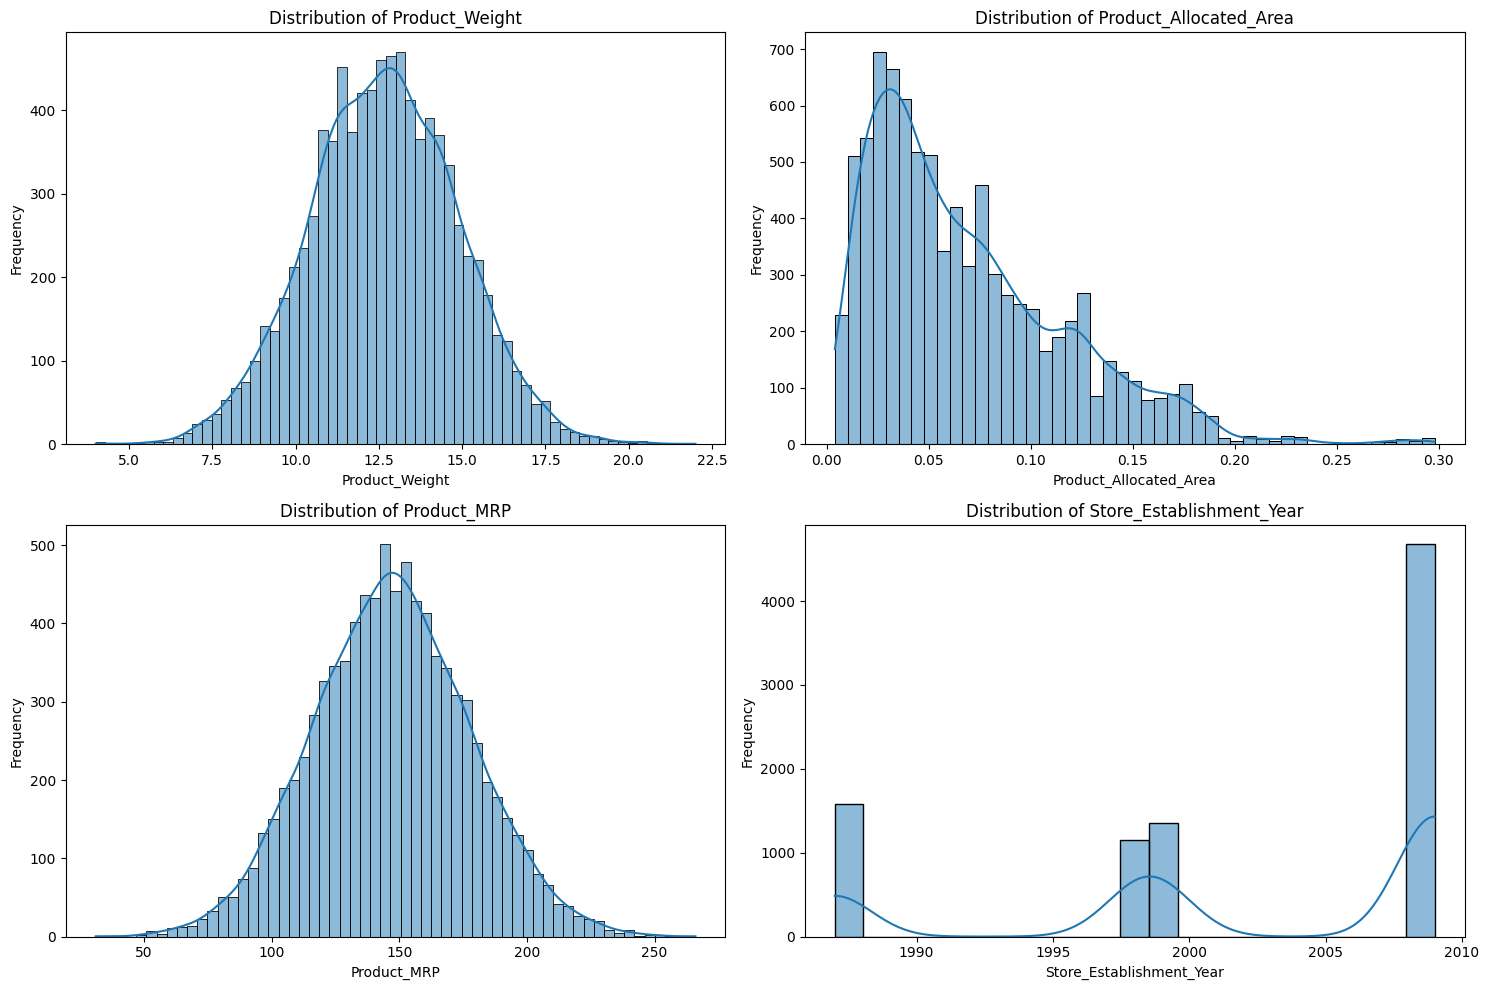

In [15]:
plt.figure(figsize=(15, 10))
for i, feature in enumerate(numeric_features):
    plt.subplot(2, 2, i + 1) # Adjust the grid size if you have more numerical features
    sns.histplot(dataset[feature], kde=True)
    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')
plt.tight_layout()
plt.show()


### Distribution of the Target Variable

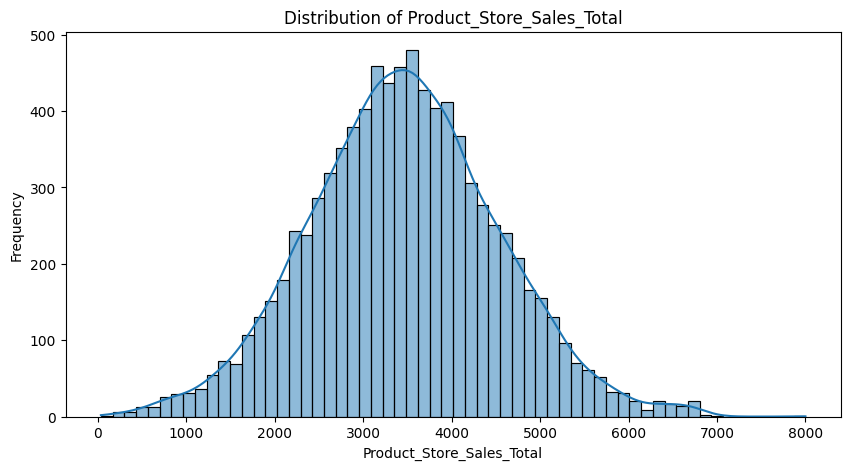

In [16]:
plt.figure(figsize=(10, 5))
sns.histplot(dataset[target], kde=True)
plt.title(f'Distribution of {target}')
plt.xlabel(target)
plt.ylabel('Frequency')
plt.show()

### Value Counts and Distribution of Categorical Features


Value counts for Product_Id:
Product_Id
FD306     1
FD6114    1
FD7839    1
FD5075    1
FD8233    1
         ..
FD1387    1
FD1231    1
FD5276    1
FD8553    1
FD6027    1
Name: count, Length: 8763, dtype: int64


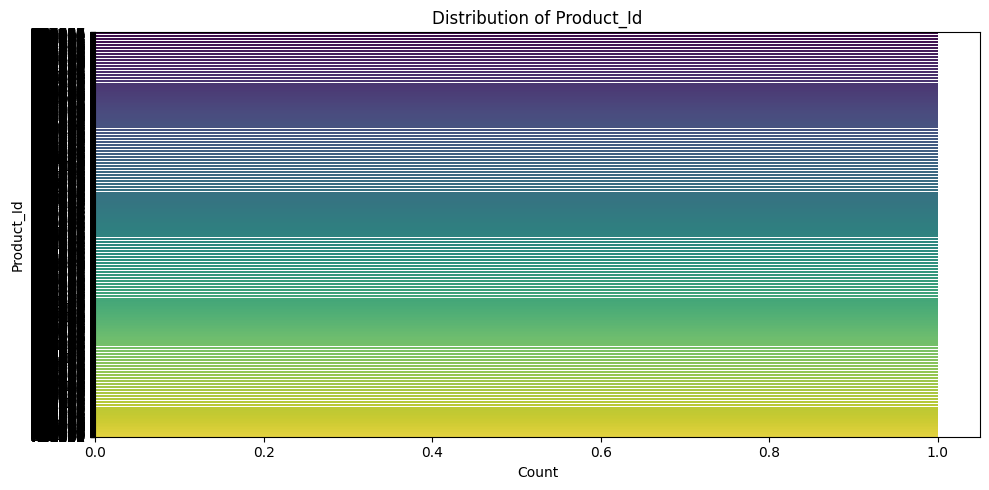


Value counts for Product_Sugar_Content:
Product_Sugar_Content
Low Sugar    4885
Regular      2251
No Sugar     1519
reg           108
Name: count, dtype: int64


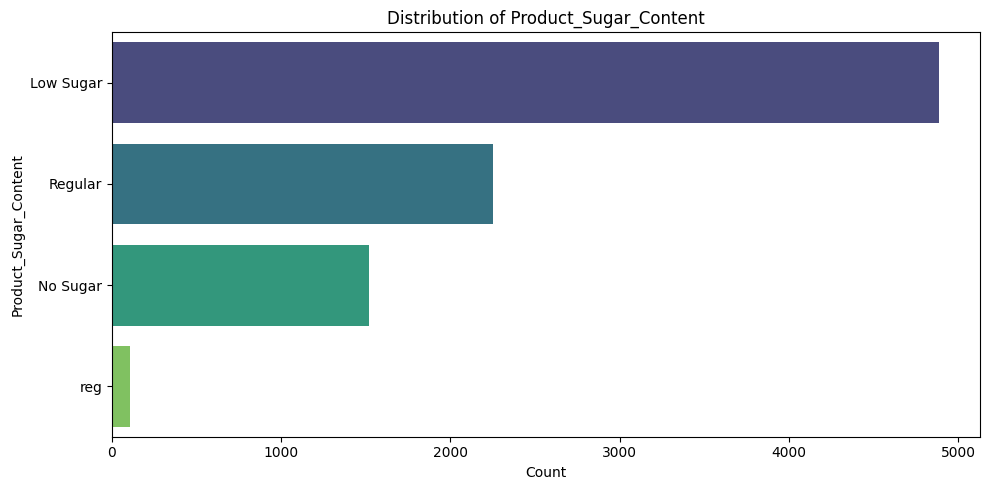


Value counts for Product_Type:
Product_Type
Fruits and Vegetables    1249
Snack Foods              1149
Frozen Foods              811
Dairy                     796
Household                 740
Baking Goods              716
Canned                    677
Health and Hygiene        628
Meat                      618
Soft Drinks               519
Breads                    200
Hard Drinks               186
Others                    151
Starchy Foods             141
Breakfast                 106
Seafood                    76
Name: count, dtype: int64


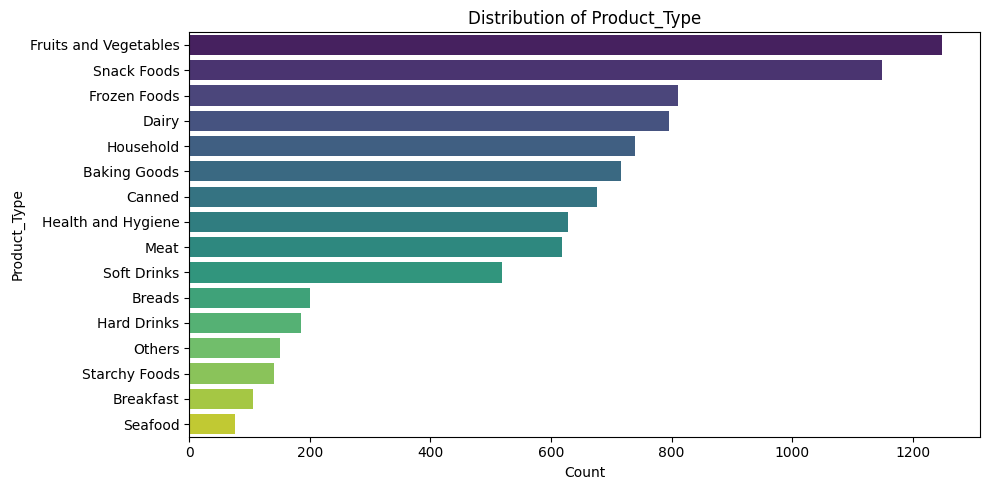


Value counts for Store_Id:
Store_Id
OUT004    4676
OUT001    1586
OUT003    1349
OUT002    1152
Name: count, dtype: int64


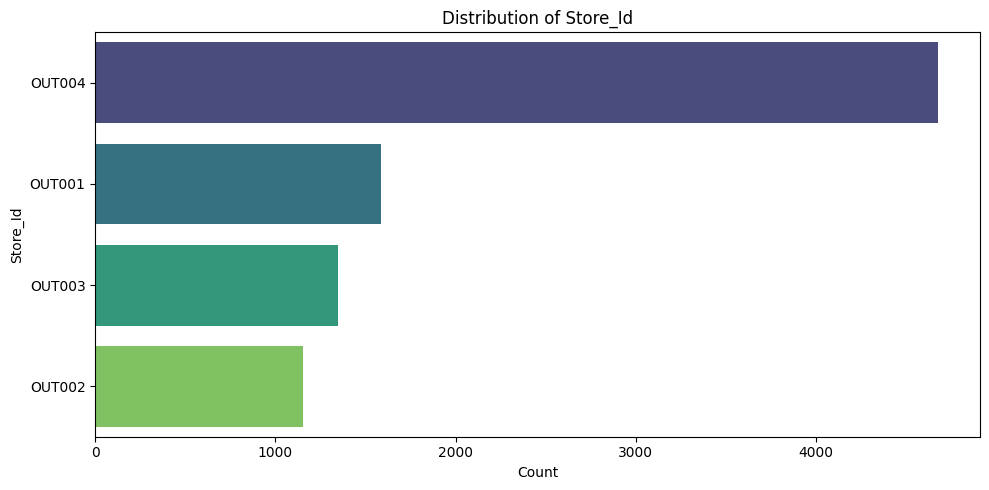


Value counts for Store_Size:
Store_Size
Medium    6025
High      1586
Small     1152
Name: count, dtype: int64


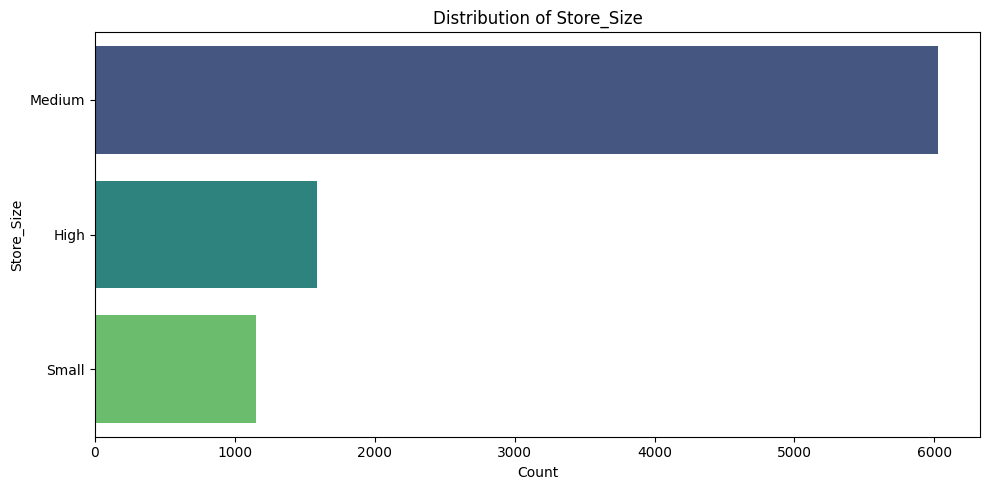


Value counts for Store_Location_City_Type:
Store_Location_City_Type
Tier 2    6262
Tier 1    1349
Tier 3    1152
Name: count, dtype: int64


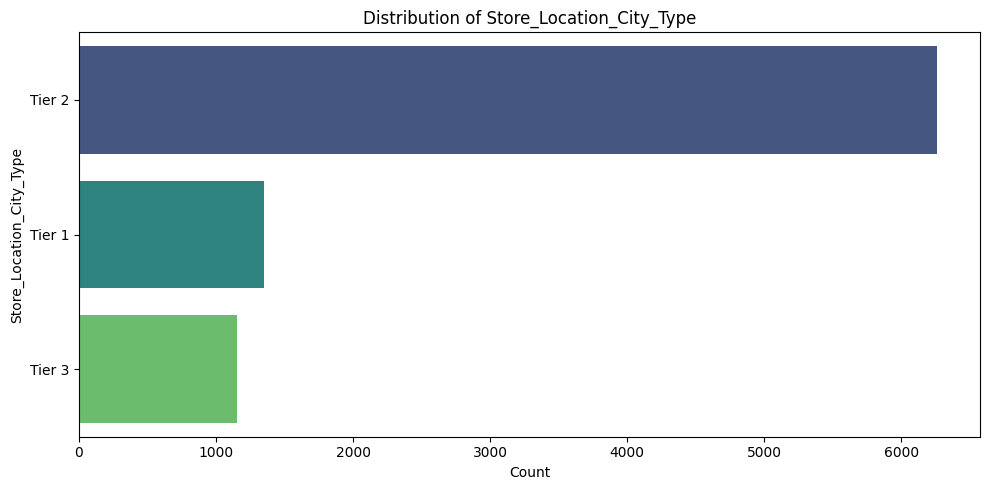


Value counts for Store_Type:
Store_Type
Supermarket Type2     4676
Supermarket Type1     1586
Departmental Store    1349
Food Mart             1152
Name: count, dtype: int64


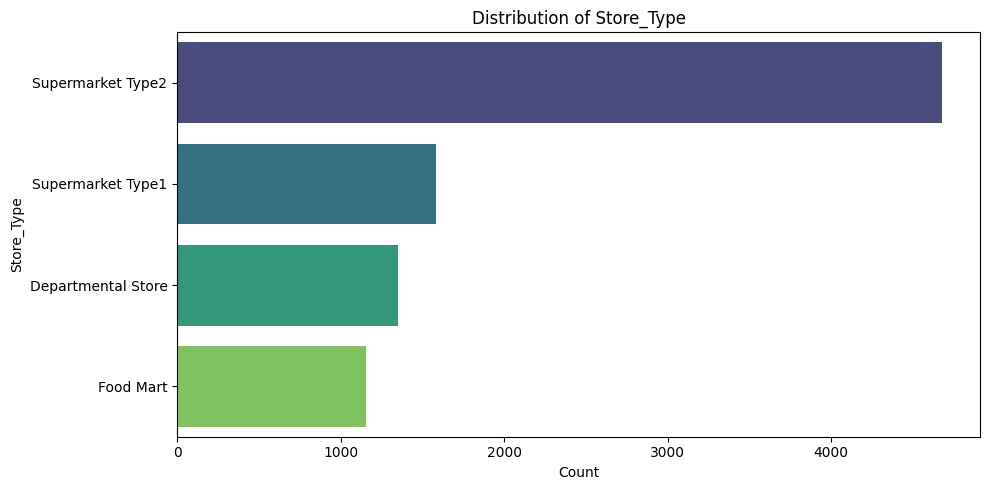

In [17]:
for feature in categorical_features:
    print(f"\nValue counts for {feature}:")
    print(dataset[feature].value_counts())
    plt.figure(figsize=(10, 5))
    sns.countplot(y=dataset[feature], order=dataset[feature].value_counts().index, palette='viridis')
    plt.title(f'Distribution of {feature}')
    plt.xlabel('Count')
    plt.ylabel(feature)
    plt.tight_layout()
    plt.show()


Univariate overview-

Numerical Features:

* **Product_Weight:** The weights are distributed fairly symmetrically around a mean of approximately 12.65. Most products fall within a common weight range.
* **Product_Allocated_Area:** This feature shows a right-skewed distribution. A significant number of products have smaller allocated display areas, with fewer products having larger areas.
* **Product_MRP:** The Maximum Retail Price also appears to be relatively symmetrically distributed around a mean of about 147.03.
* **Store_Establishment_Year:** There are only 4 distinct values (1987, 1998, 1999, 2009) because there are only 4 stores; 2009 dominates because the store opened that year (OUT004) accounts for the most rows.
* **Product_Store_Sales_Total (target):** Roughly bell-shaped, centred around ~3,450, ranging from ~33 to ~8,000.

Categorical Features:

* **Product_Id:** Every value is unique (8,763 IDs), so the raw ID carries no repeatable pattern for a model. However, its first two letters (FD / DR / NC) do encode the product family — this is used for feature engineering below.
* **Product_Sugar_Content:** Low Sugar is the most common (~56%), followed by Regular (~26%) and No Sugar (~17%). There is also an inconsistent label **`reg`** (~1%) which is the same category as `Regular` and is fixed during preprocessing.
* **Product_Type:** Fruits and Vegetables (~14%) and Snack Foods (~13%) are the most frequent; Seafood (~1%) is the least frequent.
* **Store_Id:** There are only 4 stores. OUT004 accounts for ~53% of the records.
* **Store_Size / Store_Location_City_Type / Store_Type:** Medium stores (~69%), Tier 2 cities (~71%) and Supermarket Type2 (~53%) dominate — again driven by OUT004.

## Bivariate Analysis

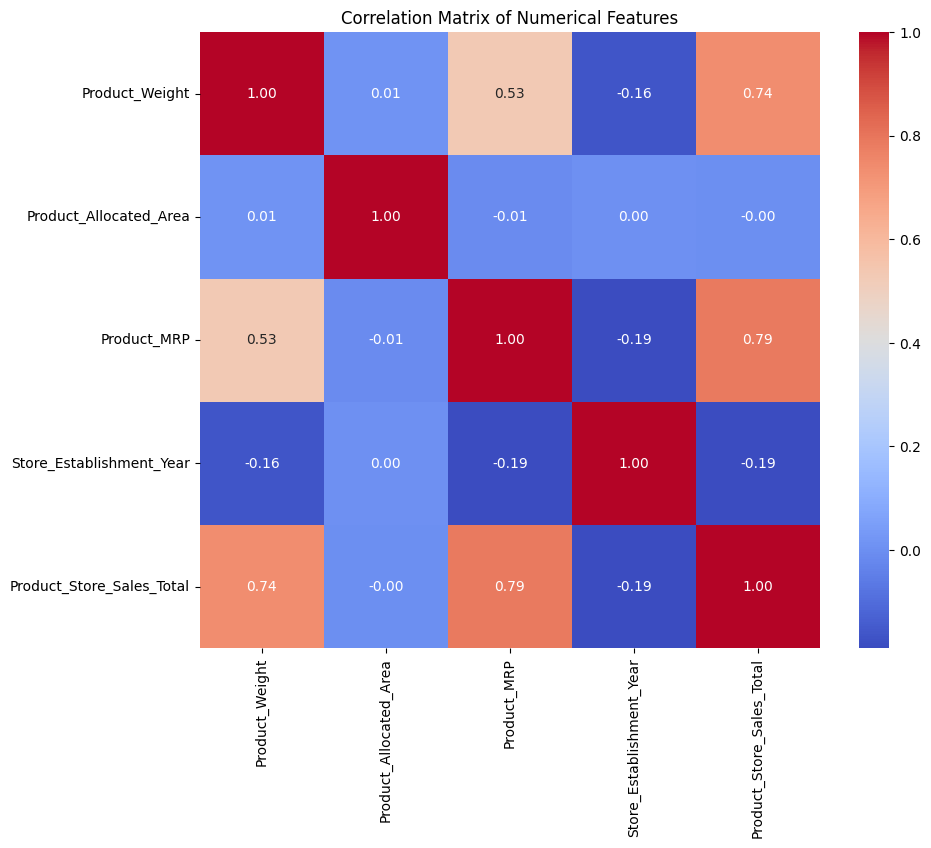

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_cols = dataset.select_dtypes(include=['float64', 'int64']).columns

# Calculate the correlation matrix
correlation_matrix = dataset[numerical_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numerical Features')
plt.show()

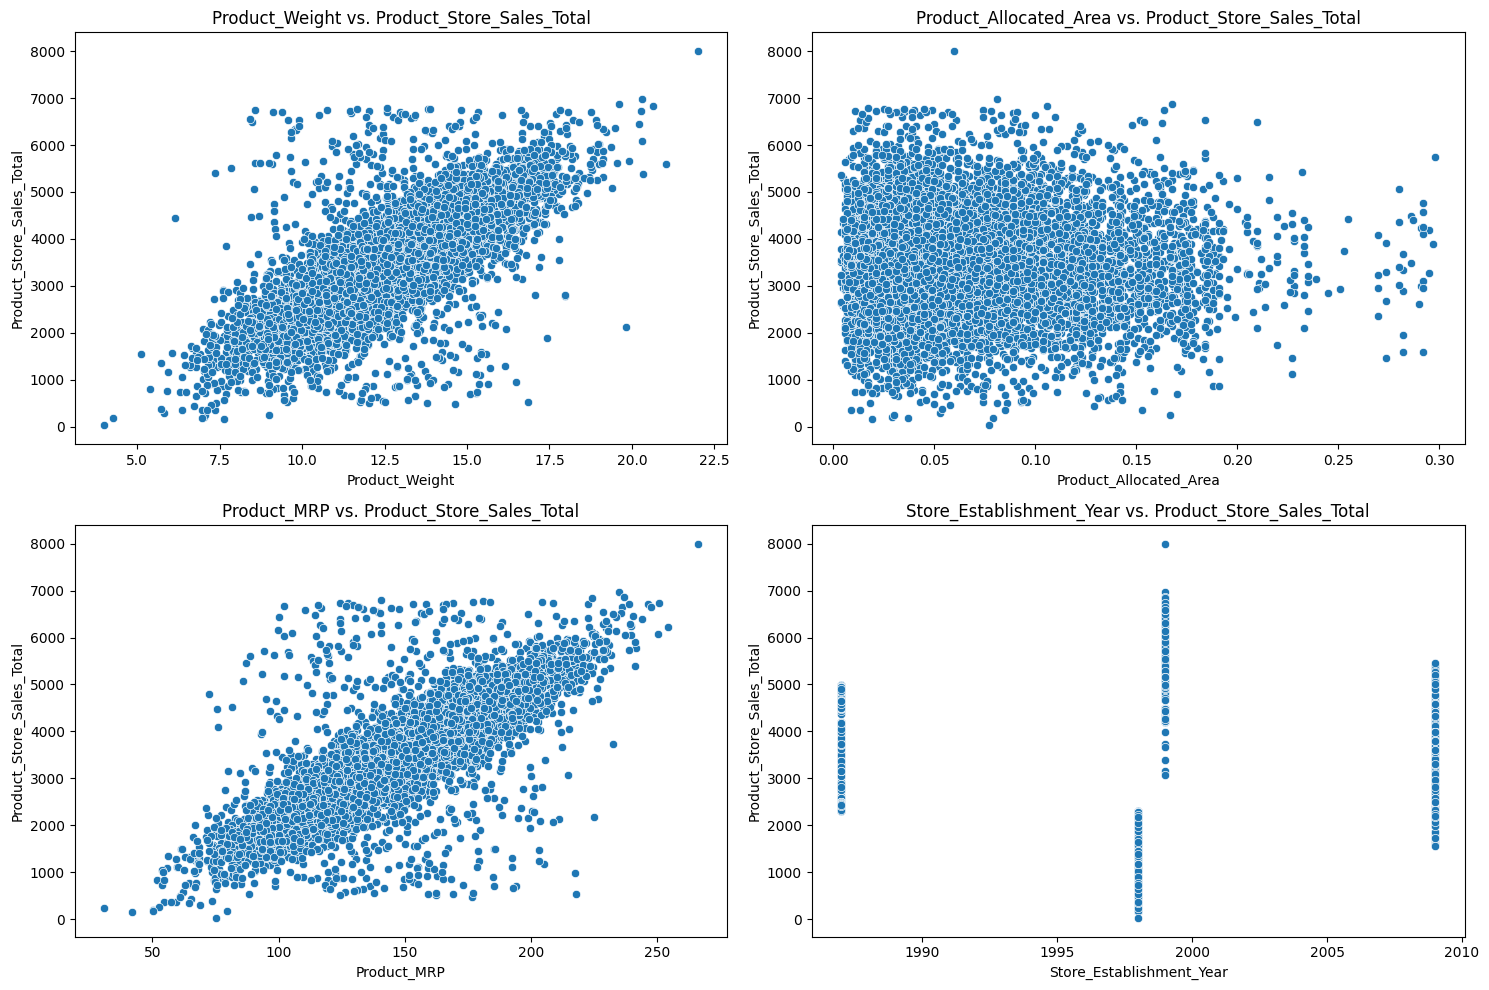

In [19]:
# Plot scatter plots for numerical features vs. Product_Store_Sales_Total
# Exclude the target variable itself from the independent numerical features for these plots
features_for_scatter = [col for col in numerical_cols if col != 'Product_Store_Sales_Total']

plt.figure(figsize=(15, 10))
for i, col in enumerate(features_for_scatter):
    plt.subplot(2, 2, i + 1) # Adjust subplot grid as needed
    sns.scatterplot(x=dataset[col], y=dataset['Product_Store_Sales_Total'])
    plt.title(f'{col} vs. Product_Store_Sales_Total')
    plt.xlabel(col)
    plt.ylabel('Product_Store_Sales_Total')
plt.tight_layout()
plt.show()

Skipping box plot for 'Product_Id' due to high cardinality (8763 unique values).
Skipping box plot for 'Store_Id' due to high cardinality (4 unique values).


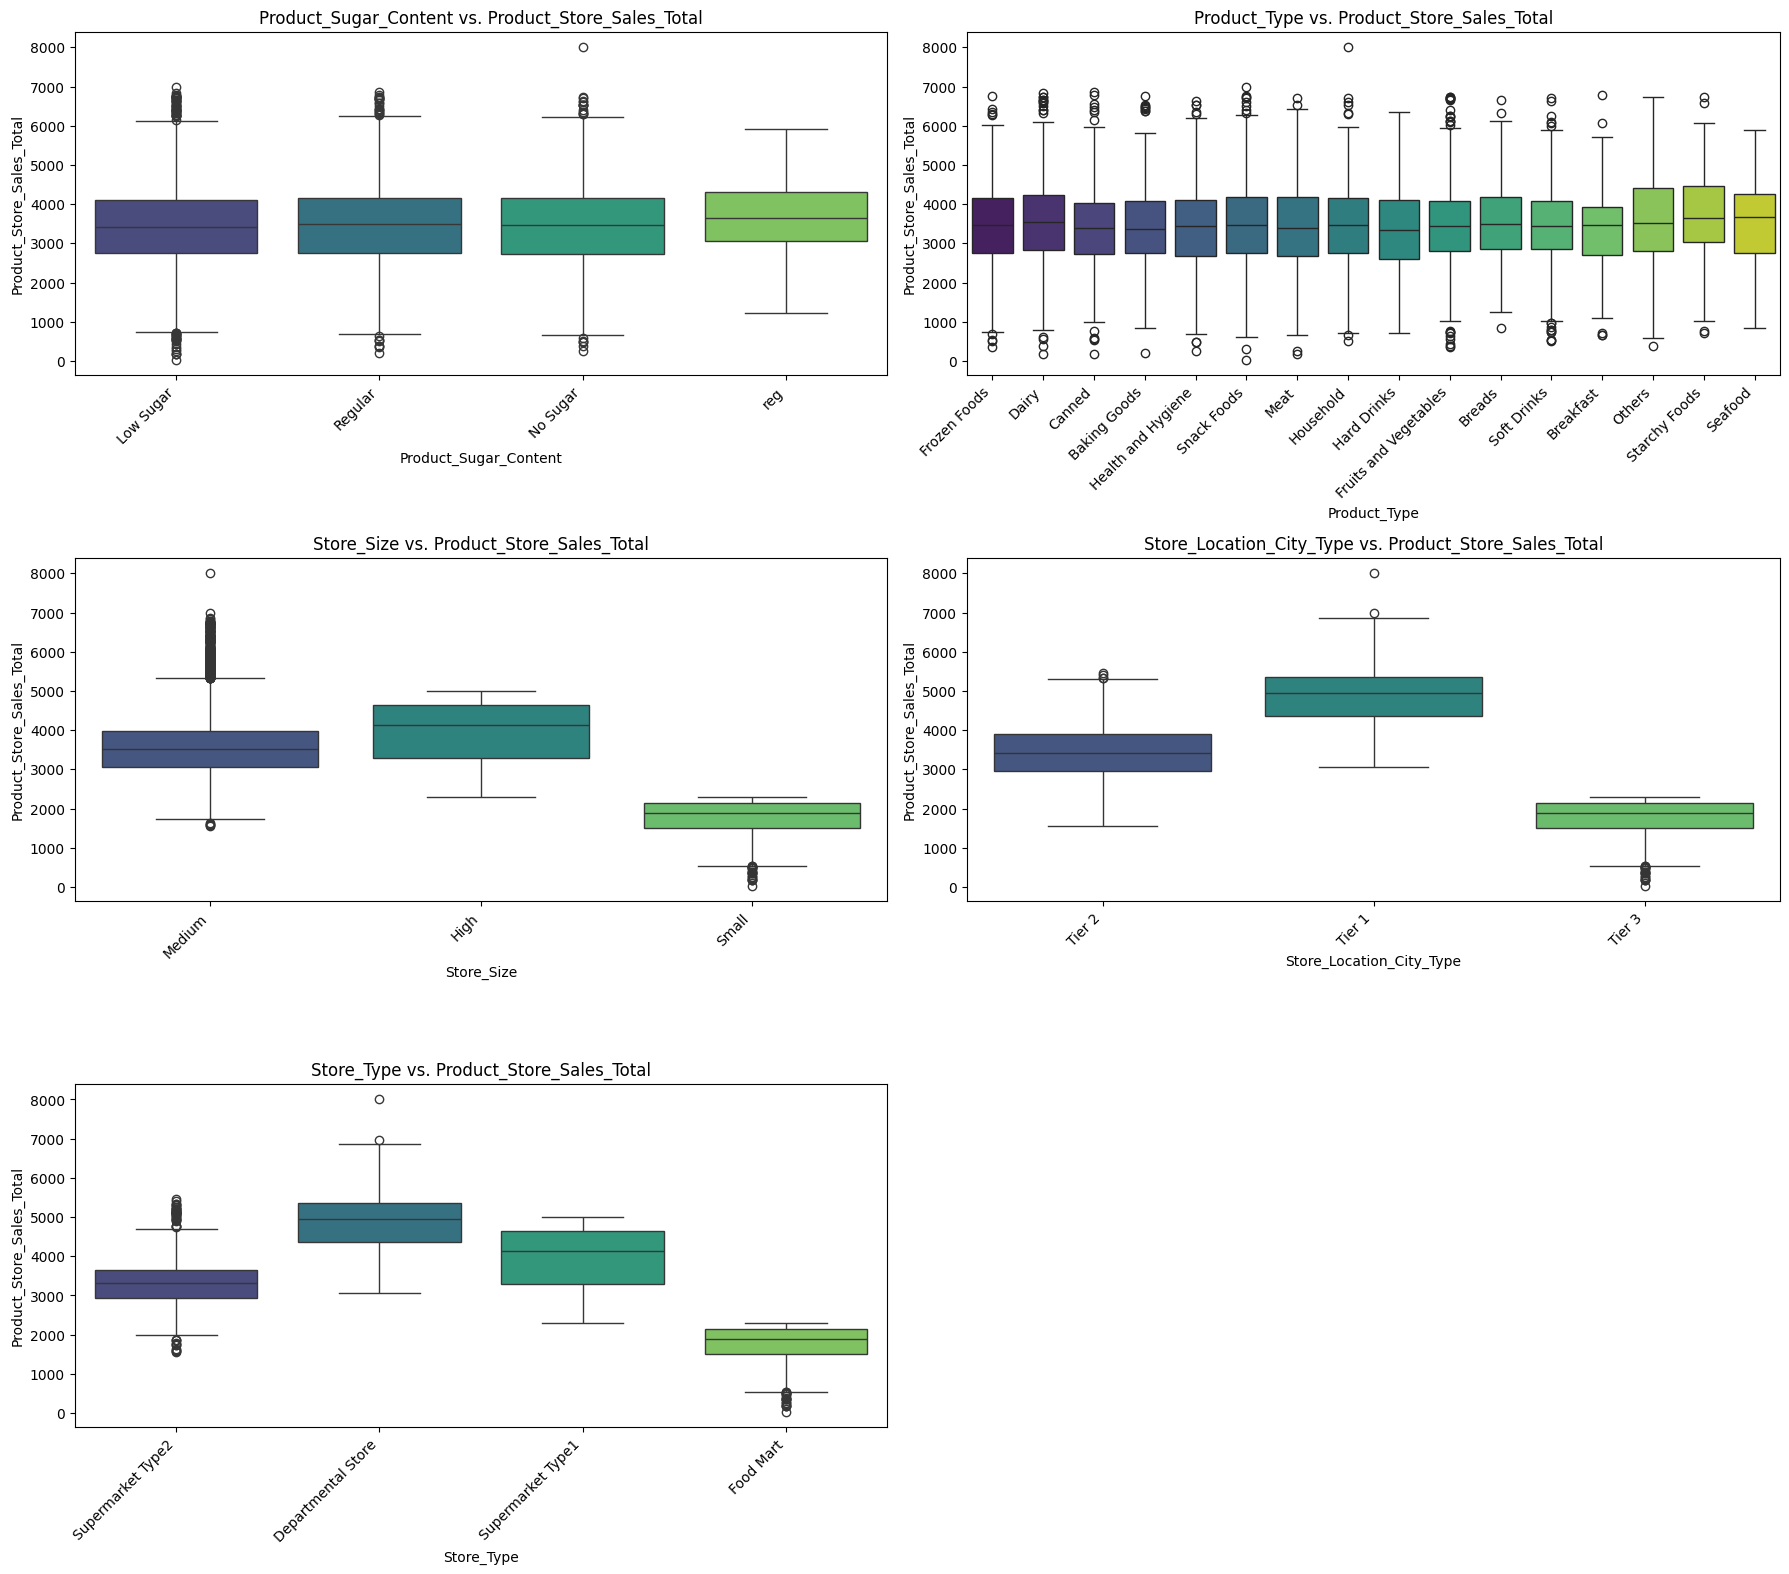

In [20]:
categorical_cols = dataset.select_dtypes(include=['object']).columns

# Plot box plots for categorical features vs. Product_Store_Sales_Total
plt.figure(figsize=(18, 25))

plot_index = 1
for col in categorical_cols:
    # Skip Product_Id and Store_Id for direct box plots due to high cardinality
    if col not in ['Product_Id', 'Store_Id']:
        plt.subplot(len(categorical_cols) - 2, 2, plot_index) # Adjust subplot grid
        sns.boxplot(x=dataset[col], y=dataset['Product_Store_Sales_Total'], palette='viridis')
        plt.title(f'{col} vs. Product_Store_Sales_Total')
        plt.xlabel(col)
        plt.ylabel('Product_Store_Sales_Total')
        plt.xticks(rotation=45, ha='right')
        plot_index += 1
    else:
        print(f"Skipping box plot for '{col}' due to high cardinality ({dataset[col].nunique()} unique values).")
        # Optionally, you could show mean sales per category for very high cardinality features
        # mean_sales = dataset.groupby(col)['Product_Store_Sales_Total'].mean().sort_values(ascending=False)
        # print(f"Top 5 mean sales by {col}:\n{mean_sales.head()}")

plt.tight_layout()
plt.show()


### Bivariate Overview

**Numerical Features vs. Sales:**

*   **Product_Weight and Product_MRP** show a strong positive correlation with `Product_Store_Sales_Total` (0.74 and 0.79 respectively). This suggests that heavier products and products with higher Maximum Retail Price tend to generate more sales.
*   **Product_Allocated_Area** has a negligible correlation with `Product_Store_Sales_Total` (0.00). This indicates that the allocated display area alone doesn't seem to be a significant driver of sales.
*   **Store_Establishment_Year** has a weak negative correlation (-0.19) with `Product_Store_Sales_Total`, meaning **older** stores tend to have slightly **higher** sales per product (newer establishment year → lower sales), though the relationship is not very strong.

**Categorical Features vs. Sales (from Box Plots):**

*   **Product_Sugar_Content:** Median sales are very similar across sugar categories (~3,430–3,650), so sugar content on its own is not a strong driver of sales.
*   **Product_Type:** Median sales per product are similar across product types (~3,340–3,680). Categories such as Fruits and Vegetables and Snack Foods drive the most *total* revenue because they are sold most often, not because each item sells more.
*   **Store_Size:** 'High' and 'Medium' sized stores tend to generate higher sales than 'Small' stores, which exhibit the lowest sales figures.
*   **Store_Location_City_Type:** 'Tier 1' cities show the highest median sales, followed by 'Tier 2', and then 'Tier 3' cities, indicating a clear hierarchy in sales performance based on city type.
*   **Store_Type:** 'Departmental Store' and 'Supermarket Type1' record the highest median sales per product, with 'Food Mart' showing the lowest. (Supermarket Type2 / OUT004 still generates the largest *total* revenue because of its volume.)

Overall, the bivariate analysis highlights key features like `Product_Weight`, `Product_MRP`, `Store_Size`, `Store_Location_City_Type`, and `Store_Type` as potentially strong predictors of `Product_Store_Sales_Total`.

# **Data Preprocessing**

## Fixing inconsistent category labels

`Product_Sugar_Content` contains both `Regular` and `reg`, which refer to the same category. We replace `reg` with `Regular`.

In [21]:
dataset['Product_Sugar_Content'] = dataset['Product_Sugar_Content'].replace('reg', 'Regular')
dataset['Product_Sugar_Content'].value_counts()

,count
Product_Sugar_Content,
Low Sugar,4885
Regular,2359
No Sugar,1519


## Feature Engineering

Three new features are created:

1. **`Product_Id_char`** – the first two letters of `Product_Id`. The raw ID is unique per row (useless to a model), but the prefix encodes the product family: **FD** = food, **DR** = drinks, **NC** = non-consumables (household, health & hygiene, others).
2. **`Store_Age_Years`** – `2025 - Store_Establishment_Year`. Age is more interpretable than a calendar year and keeps working for future years.
3. **`Product_Type_Category`** – groups the 16 product types into **Perishables** vs **Non Perishables**. This reduces the number of categories (less sparse one-hot encoding) and reflects a distinction that matters for inventory planning.

In [22]:
# 1. Product family from the Product_Id prefix
dataset['Product_Id_char'] = dataset['Product_Id'].str[:2]

# Check which product types fall under each prefix
for prefix in dataset['Product_Id_char'].unique():
    print(prefix, '->', dataset.loc[dataset['Product_Id_char'] == prefix, 'Product_Type'].unique())

FD -> ['Frozen Foods' 'Dairy' 'Canned' 'Baking Goods' 'Snack Foods' 'Meat'
 'Fruits and Vegetables' 'Breads' 'Breakfast' 'Starchy Foods' 'Seafood']
NC -> ['Health and Hygiene' 'Household' 'Others']
DR -> ['Hard Drinks' 'Soft Drinks']


In [23]:
# 2. Store age in years
dataset['Store_Age_Years'] = 2025 - dataset['Store_Establishment_Year']
dataset['Store_Age_Years'].value_counts()

,count
Store_Age_Years,
16,4676
38,1586
26,1349
27,1152


In [24]:
# 3. Perishable vs non-perishable product groups
perishables = ["Dairy", "Meat", "Fruits and Vegetables", "Breakfast", "Breads", "Seafood"]

dataset['Product_Type_Category'] = np.where(
    dataset['Product_Type'].isin(perishables), "Perishables", "Non Perishables"
)
dataset['Product_Type_Category'].value_counts()

,count
Product_Type_Category,
Non Perishables,5718
Perishables,3045


## Outlier Check

,lower_bound,upper_bound,n_outliers,pct_outliers
Product_Weight,6.605,18.725,54.0,0.62
Product_Allocated_Area,-0.067,0.194,104.0,1.19
Product_MRP,64.022,229.723,57.0,0.65
Product_Store_Sales_Total,686.540,6220.340,119.0,1.36


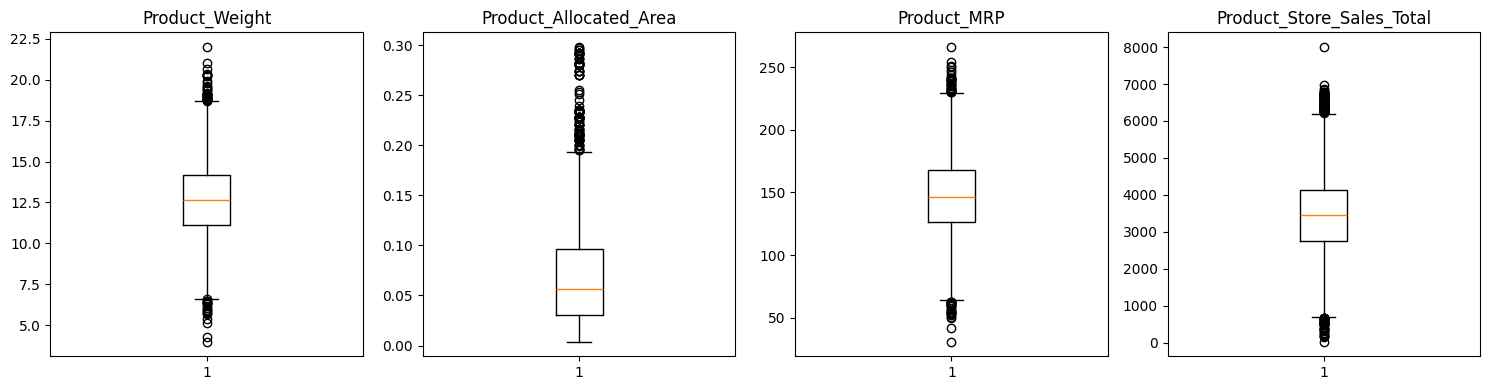

In [25]:
# Outlier detection using the IQR rule (values beyond 1.5 * IQR from the quartiles)
outlier_cols = ['Product_Weight', 'Product_Allocated_Area', 'Product_MRP', 'Product_Store_Sales_Total']

outlier_summary = {}
for col in outlier_cols:
    q1, q3 = dataset[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((dataset[col] < lower) | (dataset[col] > upper)).sum()
    outlier_summary[col] = {'lower_bound': round(lower, 3), 'upper_bound': round(upper, 3),
                            'n_outliers': n_out, 'pct_outliers': round(100 * n_out / len(dataset), 2)}

display(pd.DataFrame(outlier_summary).T)

plt.figure(figsize=(15, 4))
for i, col in enumerate(outlier_cols):
    plt.subplot(1, 4, i + 1)
    plt.boxplot(dataset[col], whis=1.5)
    plt.title(col)
plt.tight_layout()
plt.show()

**Outlier treatment decision: left unchanged.**

- Detection method: IQR rule (1.5 × IQR), visualised with box plots.
- Each column has only a small share of outliers (roughly 1% or less of rows).
- The values are realistic (e.g., a premium product with a high MRP, a large display area, or a high-revenue item at the premium store OUT003), not data-entry errors.
- Removing or capping them would hide exactly the high/low-revenue cases the business needs to forecast, and tree-based models (Random Forest, XGBoost) are robust to outliers anyway.

## Dropping columns not used for modeling

- **`Product_Id`** – unique per row; replaced by `Product_Id_char`. Keeping it would create ~7,000 one-hot columns that never appear in new data.
- **`Product_Type`** – summarised by `Product_Type_Category` (and `Product_Id_char`).
- **`Store_Establishment_Year`** – replaced by `Store_Age_Years`.
- **`Store_Id`** – each of the 4 stores has a unique combination of `Store_Type`, `Store_Size`, `Store_Location_City_Type` and age, so the ID adds no extra information. Using store attributes also lets the model score a new store.

The remaining feature set matches the columns expected by the batch file (`Batch_Data_SuperKart.csv`) and the API.

In [26]:
dataset = dataset.drop(columns=['Product_Id', 'Product_Type', 'Store_Id', 'Store_Establishment_Year'])
print(dataset.shape)
dataset.head()

(8763, 11)


,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_MRP,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total,Product_Id_char,Store_Age_Years,Product_Type_Category
0,12.66,Low Sugar,0.027,117.08,Medium,Tier 2,Supermarket Type2,2842.40,FD,16,Non Perishables
1,16.54,Low Sugar,0.144,171.43,Medium,Tier 1,Departmental Store,4830.02,FD,26,Perishables
2,14.28,Regular,0.031,162.08,High,Tier 2,Supermarket Type1,4130.16,FD,38,Non Perishables
3,12.10,Low Sugar,0.112,186.31,High,Tier 2,Supermarket Type1,4132.18,FD,38,Non Perishables
4,9.57,No Sugar,0.010,123.67,Small,Tier 3,Food Mart,2279.36,NC,27,Non Perishables


## Data Preparation for Modeling

In [27]:
# Define the target variable for the regression task
target = 'Product_Store_Sales_Total'

# List of numerical features in the dataset
numeric_features = dataset.select_dtypes(include=['float64', 'int64']).columns.tolist()
numeric_features.remove(target)  # Remove target from numerical features

# List of categorical features in the dataset
categorical_features = dataset.select_dtypes(include=['object']).columns.tolist()

print(f"Target Variable: {target}")
print(f"Numerical Features: {numeric_features}")
print(f"Categorical Features: {categorical_features}")

Target Variable: Product_Store_Sales_Total
Numerical Features: ['Product_Weight', 'Product_Allocated_Area', 'Product_MRP', 'Store_Age_Years']
Categorical Features: ['Product_Sugar_Content', 'Store_Size', 'Store_Location_City_Type', 'Store_Type', 'Product_Id_char', 'Product_Type_Category']


In [28]:
# Define predictor matrix (X) and target variable (y)
X = dataset.drop(columns=[target])
y = dataset[target]

In [29]:
# Split the dataset into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,              # Predictors (X) and target variable (y)
    test_size=0.2,     # 20% of the data is reserved for testing
    random_state=42    # Ensures reproducibility by setting a fixed random seed
)

In [30]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Create a preprocessing pipeline for numerical and categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features) # Apply OneHotEncoder to categorical features
    ]
)

### Data Preprocessing Overview

The data preprocessing phase involved these steps:

1.  **Data cleaning:** No duplicates or missing values were found. The inconsistent `reg` label was merged into `Regular`.
2.  **Feature engineering:** Created `Product_Id_char`, `Store_Age_Years` and `Product_Type_Category`, and dropped `Product_Id`, `Product_Type`, `Store_Id` and `Store_Establishment_Year`.
3.  **Outliers:** Detected with the IQR rule and intentionally left unchanged (genuine values).
4.  **Defining Target and Features:** The target is `Product_Store_Sales_Total`; the remaining columns are split into `numeric_features` and `categorical_features`.
5.  **Data Splitting:** 80/20 train/test split (`random_state=42`) so performance is measured on unseen data.
6.  **Preprocessing Pipeline:** A `ColumnTransformer` applies `StandardScaler` to numerical features and `OneHotEncoder(handle_unknown='ignore')` to categorical features. It is part of the model pipeline, so the exact same transformations are applied at prediction time in the API.

# **Model Building**

## Choosing the Primary Evaluation Metric

**Primary metric: RMSE (Root Mean Squared Error)**

RMSE is used consistently for hyperparameter tuning, model comparison and final model selection. Why it fits SuperKart's objective:

- **Same units as revenue.** RMSE is expressed in the same currency units as `Product_Store_Sales_Total`, so "RMSE = 280" means a typical forecast is off by about 280 in sales — easy for business teams to interpret.
- **Penalises large misses more heavily.** Because errors are squared, a few big forecasting errors (which cause serious overstocking or stock-outs) are punished more than many small ones. For inventory and procurement planning, avoiding large misses matters most.
- **Directly optimisable.** `GridSearchCV` supports `scoring='neg_root_mean_squared_error'`, so the models are tuned on the same metric used to compare them.

MAE, R² and MAPE are still printed by the helper function for context, but all decisions are made on **test RMSE**, and the **gap between train and test RMSE** is used to judge overfitting.

## Define functions for Model Evaluation

In [31]:
# function to compute adjusted R-squared
def adj_r2_score(predictors, targets, predictions):
    r2 = r2_score(targets, predictions)
    n = predictors.shape[0]
    k = predictors.shape[1]
    return 1 - ((1 - r2) * (n - 1) / (n - k - 1))


# function to compute different metrics to check performance of a regression model
def model_performance_regression(model, predictors, target):
    """
    Function to compute different metrics to check regression model performance

    model: regressor
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    pred = model.predict(predictors)

    r2 = r2_score(target, pred)  # to compute R-squared
    adjr2 = adj_r2_score(predictors, target, pred)  # to compute adjusted R-squared
    rmse = np.sqrt(mean_squared_error(target, pred))  # to compute RMSE
    mae = mean_absolute_error(target, pred)  # to compute MAE
    mape = mean_absolute_percentage_error(target, pred)  # to compute MAPE

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {
            "RMSE": rmse,
            "MAE": mae,
            "R-squared": r2,
            "Adj. R-squared": adjr2,
            "MAPE": mape,
        },
        index=[0],
    )

    return df_perf

The ML models to be built can be any two out of the following:
1. Decision Tree
2. Bagging
3. Random Forest
4. AdaBoost
5. Gradient Boosting
6. XGBoost

### **Model Selection Justification**
From the list of available algorithms, I have selected **Random Forest** and **XGBoost** for the following reasons:

1. **Random Forest:** This is a robust, highly versatile bagging ensemble method. It operates by constructing a multitude of decision trees and outputting the average prediction. It acts as an excellent, strong baseline because it is less prone to overfitting than individual decision trees and handles complex datasets with mixed data types very well.
2. **XGBoost:** eXtreme Gradient Boosting is an advanced, highly optimized implementation of the gradient boosting framework. It is widely considered state-of-the-art for tabular data regression tasks due to its execution speed, regularization features (to prevent overfitting), and ability to capture complex, non-linear relationships by sequentially building trees to correct past errors.

## Baseline Models

In [32]:
# 1. Build and train Random Forest Pipeline
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(random_state=42))
])
rf_pipeline.fit(X_train, y_train)

rf_train_perf = model_performance_regression(rf_pipeline, X_train, y_train)
rf_test_perf = model_performance_regression(rf_pipeline, X_test, y_test)

print("--- Random Forest Regressor (baseline) ---")
print("Training Performance:")
display(rf_train_perf)
print("Testing Performance:")
display(rf_test_perf)


# 2. Build and train XGBoost Pipeline
xgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', XGBRegressor(random_state=42))
])
xgb_pipeline.fit(X_train, y_train)

xgb_train_perf = model_performance_regression(xgb_pipeline, X_train, y_train)
xgb_test_perf = model_performance_regression(xgb_pipeline, X_test, y_test)

print("\n--- XGBoost Regressor (baseline) ---")
print("Training Performance:")
display(xgb_train_perf)
print("Testing Performance:")
display(xgb_test_perf)

--- Random Forest Regressor (baseline) ---
Training Performance:


,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,106.978437,40.242381,0.989908,0.989894,0.014962


Testing Performance:


,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,285.793748,109.835291,0.928417,0.928006,0.03938



--- XGBoost Regressor (baseline) ---
Training Performance:


,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,139.413459,63.001258,0.982861,0.982837,0.022877


Testing Performance:


,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,308.502036,136.599289,0.916589,0.91611,0.04977


In [33]:
# Baseline RMSE summary: train vs test and the generalization gap
baseline_rmse = pd.DataFrame({
    'Train RMSE': [rf_train_perf['RMSE'][0], xgb_train_perf['RMSE'][0]],
    'Test RMSE': [rf_test_perf['RMSE'][0], xgb_test_perf['RMSE'][0]],
}, index=['Random Forest (baseline)', 'XGBoost (baseline)'])
baseline_rmse['Test / Train RMSE ratio'] = baseline_rmse['Test RMSE'] / baseline_rmse['Train RMSE']
baseline_rmse.round(2)

,Train RMSE,Test RMSE,Test / Train RMSE ratio
Random Forest (baseline),106.98,285.79,2.67
XGBoost (baseline),139.41,308.50,2.21


**Baseline interpretation (RMSE):**

- Both baseline models have a much lower RMSE on the training set than on the test set (test RMSE is roughly 2–3× the train RMSE). The default settings let trees grow fully, so the models **memorise the training data — a sign of overfitting**.
- Even so, test RMSE (~285–310) is small relative to typical sales values (~3,450), so both models already generalise reasonably well.
- Random Forest has the lower test RMSE of the two baselines.
- Hyperparameter tuning (next section) aims to **lower test RMSE** and **narrow the train–test gap**.

# **Model Performance Improvement - Hyperparameter Tuning**

In [34]:
# Hyperparameter grid for Random Forest
# (min_samples_leaf / max_depth limit how closely trees fit the training data -> reduces overfitting)
param_grid_rf = {
    'regressor__n_estimators': [100, 200],
    'regressor__max_depth': [10, 20, None],
    'regressor__min_samples_split': [2, 5],
    'regressor__min_samples_leaf': [1, 3]
}

# Hyperparameter grid for XGBoost
param_grid_xgb = {
    'regressor__n_estimators': [100, 200],
    'regressor__learning_rate': [0.05, 0.1, 0.2],
    'regressor__max_depth': [3, 5, 7],
    'regressor__subsample': [0.7, 0.8, 0.9]
}

# Both grid searches optimise the primary metric: RMSE
scoring_metric = 'neg_root_mean_squared_error'

# Tuning Random Forest
print("Tuning Random Forest...")
grid_search_rf = GridSearchCV(rf_pipeline, param_grid_rf, cv=3, scoring=scoring_metric, n_jobs=-1, verbose=1)
grid_search_rf.fit(X_train, y_train)
print(f"Best parameters for Random Forest: {grid_search_rf.best_params_}")
print(f"Best cross-validated RMSE (Random Forest): {-grid_search_rf.best_score_:.2f}")
best_rf_model = grid_search_rf.best_estimator_

# Tuning XGBoost
print("\nTuning XGBoost...")
grid_search_xgb = GridSearchCV(xgb_pipeline, param_grid_xgb, cv=3, scoring=scoring_metric, n_jobs=-1, verbose=1)
grid_search_xgb.fit(X_train, y_train)
print(f"Best parameters for XGBoost: {grid_search_xgb.best_params_}")
print(f"Best cross-validated RMSE (XGBoost): {-grid_search_xgb.best_score_:.2f}")
best_xgb_model = grid_search_xgb.best_estimator_

Tuning Random Forest...
Fitting 3 folds for each of 24 candidates, totalling 72 fits
Best parameters for Random Forest: {'regressor__max_depth': 20, 'regressor__min_samples_leaf': 3, 'regressor__min_samples_split': 2, 'regressor__n_estimators': 200}
Best cross-validated RMSE (Random Forest): 286.39

Tuning XGBoost...
Fitting 3 folds for each of 54 candidates, totalling 162 fits
Best parameters for XGBoost: {'regressor__learning_rate': 0.05, 'regressor__max_depth': 7, 'regressor__n_estimators': 100, 'regressor__subsample': 0.7}
Best cross-validated RMSE (XGBoost): 287.98


In [35]:
# Evaluate tuned models on both train and test sets
best_rf_train_perf = model_performance_regression(best_rf_model, X_train, y_train)
best_rf_test_perf = model_performance_regression(best_rf_model, X_test, y_test)
best_xgb_train_perf = model_performance_regression(best_xgb_model, X_train, y_train)
best_xgb_test_perf = model_performance_regression(best_xgb_model, X_test, y_test)

print("--- Tuned Random Forest ---")
print("Training Performance:"); display(best_rf_train_perf)
print("Testing Performance:"); display(best_rf_test_perf)

print("\n--- Tuned XGBoost ---")
print("Training Performance:"); display(best_xgb_train_perf)
print("Testing Performance:"); display(best_xgb_test_perf)

--- Tuned Random Forest ---
Training Performance:


,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,198.499238,70.134108,0.965255,0.965206,0.026653


Testing Performance:


,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,278.661835,105.36993,0.931945,0.931554,0.037993



--- Tuned XGBoost ---
Training Performance:


,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,216.078209,82.999294,0.958829,0.95877,0.030865


Testing Performance:


,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,283.206112,112.481873,0.929707,0.929303,0.041315


### **Hyperparameter Tuning Outcome**

- `GridSearchCV` evaluated every hyperparameter combination with 3-fold cross-validation, **optimising RMSE** (`neg_root_mean_squared_error`) — the same metric used to compare the models below.
- The best configurations favour more regularised trees (e.g., a larger `min_samples_leaf` for Random Forest, and a lower learning rate / row subsampling for XGBoost), which trade a slightly higher training error for better performance on unseen data.
- The tuned pipelines are saved as `best_rf_model` and `best_xgb_model` and compared against the baselines in the next section.

# **Model Performance Comparison, Final Model Selection, and Serialization**

In [36]:
# Compare all four models on the primary metric (RMSE)
comparison_df = pd.DataFrame({
    'Train RMSE': [rf_train_perf['RMSE'][0], best_rf_train_perf['RMSE'][0],
                   xgb_train_perf['RMSE'][0], best_xgb_train_perf['RMSE'][0]],
    'Test RMSE': [rf_test_perf['RMSE'][0], best_rf_test_perf['RMSE'][0],
                  xgb_test_perf['RMSE'][0], best_xgb_test_perf['RMSE'][0]],
    'Test R-squared': [rf_test_perf['R-squared'][0], best_rf_test_perf['R-squared'][0],
                       xgb_test_perf['R-squared'][0], best_xgb_test_perf['R-squared'][0]],
    'Test MAPE': [rf_test_perf['MAPE'][0], best_rf_test_perf['MAPE'][0],
                  xgb_test_perf['MAPE'][0], best_xgb_test_perf['MAPE'][0]],
}, index=['Random Forest (baseline)', 'Random Forest (tuned)', 'XGBoost (baseline)', 'XGBoost (tuned)'])

comparison_df['Test - Train RMSE gap'] = comparison_df['Test RMSE'] - comparison_df['Train RMSE']

print("Model Performance Comparison (primary metric = Test RMSE, lower is better):")
display(comparison_df.round(3))

Model Performance Comparison (primary metric = Test RMSE, lower is better):


,Train RMSE,Test RMSE,Test R-squared,Test MAPE,Test - Train RMSE gap
Random Forest (baseline),106.978,285.794,0.928,0.039,178.815
Random Forest (tuned),198.499,278.662,0.932,0.038,80.163
XGBoost (baseline),139.413,308.502,0.917,0.050,169.089
XGBoost (tuned),216.078,283.206,0.930,0.041,67.128


In [37]:
# Select the final model: the TUNED model with the lowest TEST RMSE
tuned_models = {
    'Random Forest (tuned)': best_rf_model,
    'XGBoost (tuned)': best_xgb_model,
}
final_model_name = comparison_df.loc[list(tuned_models), 'Test RMSE'].idxmin()
final_model = tuned_models[final_model_name]

print(f"Selected Final Model: {final_model_name}")
print(f"Test RMSE: {comparison_df.loc[final_model_name, 'Test RMSE']:.2f}")

Selected Final Model: Random Forest (tuned)
Test RMSE: 278.66


### **Model Comparison & Final Model Selection**

**Generalization / overfitting:**
- The baseline models show the largest train–test RMSE gap — they fit the training data almost perfectly but perform noticeably worse on the test set (overfitting).
- After tuning, training RMSE increases while test RMSE decreases, so the **gap narrows considerably**. The tuned models generalise better; they are no longer memorising the training data.

**Did tuning help?**
- Yes. For both algorithms, the tuned version has a **lower test RMSE** than its baseline, so tuning improved performance on unseen data, not just on the training data.

**Final choice: Tuned Random Forest.**
- The tuned Random Forest achieves the **lowest test RMSE** of all four models (and also the best test R² and MAPE), so it is selected for deployment.
- Trade-off noted: the tuned XGBoost has a slightly *smaller* train–test gap, but its test RMSE is higher. Since the business cares about accuracy on future (unseen) data, test RMSE is the deciding criterion, and both tuned models' gaps are small enough to indicate no serious overfitting.
- In practical terms, its typical forecasting error is under 300 in sales against an average product-store sales value of ~3,450 (MAPE ≈ 4%), which is accurate enough to support quarterly inventory and procurement planning.

In [38]:
# Create a folder for storing the backend files needed for deployment
os.makedirs("backend_files", exist_ok=True)

# Define the file path to save (serialize) the trained model pipeline (preprocessing + model)
saved_model_path = "backend_files/superkart_model.joblib"

# Save the final model pipeline using joblib
joblib.dump(final_model, saved_model_path)
print(f"Final model ({final_model_name}) saved successfully at {saved_model_path}")

Final model (Random Forest (tuned)) saved successfully at backend_files/superkart_model.joblib


In [39]:
# Load the saved model pipeline from the file and confirm it works without retraining
loaded_model = joblib.load(saved_model_path)
display(loaded_model)

y_pred_test = loaded_model.predict(X_test)
print("Predictions from loaded model (first 10):")
print(y_pred_test[:10].round(2))
print(f"Test RMSE of loaded model: {np.sqrt(mean_squared_error(y_test, y_pred_test)):.2f}")

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Product_Weight',
                                                   'Product_Allocated_Area',
                                                   'Product_MRP',
                                                   'Store_Age_Years']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Product_Sugar_Content',
                                                   'Store_Size',
                                                   'Store_Location_City_Type',
                                                   'Store_Type',
                                                   'Product_Id_char',
                                                   'Product_Type_Category'])])),
                ('regressor',
                 RandomForestRegressor(max_depth=20, min_samples_leaf=3,
                                       n_estimators=200, random_state=42))])

Predictions from loaded model (first 10):
[3390.27 3364.36 2417.2  1891.15 4697.78 3011.17 2861.92 3131.44 3298.24
 1547.42]
Test RMSE of loaded model: 278.66


# **Deployment - Backend**

## Points to note before executing the below cells
- Create a GitHub account if you don't already have one at [github.com](https://github.com)
- Generate a **Personal Access Token**
  - Make sure the token has **repo** scope (full control of private repositories)
- The serialized ML model file (`superkart_model.joblib`) should already be present in the `backend_files` folder before pushing to GitHub
- We will deploy **both the Flask backend and the Streamlit frontend as separate Docker containers** inside a GitHub Codespace, and connect them using a **Docker network**

## Flask Web Framework

Flask is a lightweight, flexible Python web framework used to build web applications and APIs quickly and easily.

Flask allows you to:
- Create web routes (URLs that users can access)
- Handle HTTP requests and responses
- Build REST APIs to expose machine learning models or other services

In [40]:
import os

# Ensure the backend directory exists (the model file was saved here above)
os.makedirs('backend_files', exist_ok=True)

flask_code = """
import pandas as pd
from flask import Flask, request, jsonify
import joblib

# Initialize the Flask application
app = Flask(__name__)

# Load the trained model pipeline (preprocessing + Random Forest) from the same directory
model = joblib.load('superkart_model.joblib')

# Features expected by the model (must match the training columns)
FEATURES = [
    'Product_Weight', 'Product_Sugar_Content', 'Product_Allocated_Area', 'Product_MRP',
    'Store_Size', 'Store_Location_City_Type', 'Store_Type',
    'Product_Id_char', 'Store_Age_Years', 'Product_Type_Category'
]

@app.route('/', methods=['GET'])
def home():
    return 'Welcome to the SuperKart Sales Prediction API'

@app.route('/v1/predict', methods=['POST'])
def predict():
    try:
        # Get data from the POST request
        data = request.get_json(force=True)
        # Keep only the expected features, in the expected order
        df = pd.DataFrame([data])[FEATURES]
        # Generate prediction using the loaded model
        prediction = model.predict(df)
        # Return the prediction as a JSON response
        return jsonify({'Sales': round(float(prediction[0]), 2)})
    except KeyError as e:
        return jsonify({'error': f'Missing feature(s): {e}'}), 400
    except Exception as e:
        return jsonify({'error': str(e)}), 400

@app.route('/v1/predictbatch', methods=['POST'])
def predict_batch():
    try:
        # Check if the post request has the file part
        if 'file' not in request.files:
            return jsonify({"error": "No file part in the request"}), 400

        file = request.files['file']

        # Check if a file was selected
        if file.filename == '':
            return jsonify({"error": "No selected file"}), 400

        # Read the CSV file into a DataFrame
        df = pd.read_csv(file)

        # Drop the target column if it exists in the uploaded data
        if 'Product_Store_Sales_Total' in df.columns:
            df = df.drop(columns=['Product_Store_Sales_Total'])

        # Generate predictions for the batch
        predictions = model.predict(df[FEATURES])

        # Format predictions as a dictionary {row index: prediction} and return as JSON
        return jsonify({str(i): round(float(pred), 2) for i, pred in enumerate(predictions)})

    except KeyError as e:
        return jsonify({'error': f'Missing column(s) in CSV: {e}'}), 400
    except Exception as e:
        return jsonify({'error': str(e)}), 400

if __name__ == '__main__':
    # Run the app on all available IPs, listening on port 7860
    app.run(host='0.0.0.0', port=7860)
"""

# Write the code to the file
with open('backend_files/app.py', 'w') as f:
    f.write(flask_code)

print("Successfully saved backend_files/app.py")

Successfully saved backend_files/app.py


## Dependencies File

In [41]:
# Versions must match the ones used to train/serialize the model in this notebook
requirements_content = """Flask==3.0.3
pandas==2.2.2
numpy==2.0.2
scikit-learn==1.6.1
xgboost==2.1.4
joblib==1.4.2
"""

with open('backend_files/requirements.txt', 'w') as f:
    f.write(requirements_content)

print("Successfully saved backend_files/requirements.txt")

Successfully saved backend_files/requirements.txt


## Dockerfile

In [42]:
dockerfile_content = """# Use a minimal base image with Python 3.9 installed
FROM python:3.9-slim

# Set the working directory inside the container to /app
WORKDIR /app

# Copy all files from the current directory on the host to the container's /app directory
COPY . .

# Install Python dependencies listed in requirements.txt
RUN pip install --no-cache-dir -r requirements.txt

# Expose the port the Flask app runs on
EXPOSE 7860

# Define the command to run the Flask app
CMD ["python", "app.py"]
"""

with open('backend_files/Dockerfile', 'w') as f:
    f.write(dockerfile_content)

print("Successfully saved backend_files/Dockerfile")

Successfully saved backend_files/Dockerfile


The `app.py` script sets up a Flask web server to serve our trained machine learning model. Here is a quick overview of how it works:

1. **Initialization**: It initializes a Flask app and loads the serialized model pipeline (`superkart_model.joblib` — the tuned Random Forest plus its preprocessing) into memory using `joblib`.
2. **Health check (`GET /`)**: Returns a welcome message so we can quickly confirm the API is running.
3. **Online Inference (`POST /v1/predict`)**: Accepts a JSON payload with the 10 model features for a single product/store, converts it to a DataFrame, and returns the predicted sales as `{"Sales": ...}`.
4. **Batch Inference (`POST /v1/predictbatch`)**: Accepts a CSV file upload, drops the target column if present, predicts all rows at once, and returns a JSON dictionary mapping row indices to predictions.
5. **Error handling**: Missing features/columns return a clear `400` error message instead of crashing.
6. **Server Configuration**: Runs on host `0.0.0.0` and port `7860` inside the Docker container.

# **Deployment - Frontend**

## Points to note before executing the below cells
- The Streamlit frontend **does not load the model itself** — every prediction is sent to the deployed Flask API.
- The two containers communicate over a **Docker network**: the frontend calls `http://backend:7860`, where `backend` is the container name given to the Flask container. Docker's internal DNS resolves it automatically.
- The backend URL can be overridden with the `BACKEND_URL` environment variable if the API is hosted elsewhere.

## Streamlit for Interactive UI

In [43]:
# Create a folder for storing the frontend files
os.makedirs("frontend_files", exist_ok=True)

streamlit_code = """
import os
import requests
import pandas as pd
import streamlit as st

# Base URL of the deployed Flask backend (container name 'backend' on the Docker network)
BACKEND_URL = os.environ.get("BACKEND_URL", "http://backend:7860").rstrip("/")

st.title("SuperKart Sales Prediction App")
st.write("This app predicts the total sales revenue (`Product_Store_Sales_Total`) of a product in a particular store "
         "by calling the deployed SuperKart prediction API.")

# ---------------- Online (single) prediction ----------------
st.header("Single Prediction")

Product_Weight = st.number_input("Product Weight", min_value=0.0, max_value=30.0, value=12.66, step=0.1)
Product_Sugar_Content = st.selectbox("Product Sugar Content", ["Low Sugar", "Regular", "No Sugar"])
Product_Allocated_Area = st.number_input("Product Allocated Area (ratio)", min_value=0.0, max_value=1.0, value=0.027, step=0.001, format="%.3f")
Product_MRP = st.number_input("Product MRP", min_value=0.0, max_value=500.0, value=117.08, step=1.0)
Store_Size = st.selectbox("Store Size", ["Small", "Medium", "High"])
Store_Location_City_Type = st.selectbox("Store Location City Type", ["Tier 1", "Tier 2", "Tier 3"])
Store_Type = st.selectbox("Store Type", ["Supermarket Type1", "Supermarket Type2", "Departmental Store", "Food Mart"])
Product_Id_char = st.selectbox("Product Family (Product ID prefix)", ["FD", "DR", "NC"],
                               help="FD = Food, DR = Drinks, NC = Non-consumables")
Store_Age_Years = st.number_input("Store Age (Years)", min_value=0, max_value=100, value=16, step=1)
Product_Type_Category = st.selectbox("Product Type Category", ["Perishables", "Non Perishables"])

product_data = {
    "Product_Weight": Product_Weight,
    "Product_Sugar_Content": Product_Sugar_Content,
    "Product_Allocated_Area": Product_Allocated_Area,
    "Product_MRP": Product_MRP,
    "Store_Size": Store_Size,
    "Store_Location_City_Type": Store_Location_City_Type,
    "Store_Type": Store_Type,
    "Product_Id_char": Product_Id_char,
    "Store_Age_Years": Store_Age_Years,
    "Product_Type_Category": Product_Type_Category,
}

if st.button("Predict Sales", type="primary"):
    try:
        response = requests.post(f"{BACKEND_URL}/v1/predict", json=product_data, timeout=30)
        if response.status_code == 200:
            predicted_sales = response.json()["Sales"]
            st.success(f"Estimated Product Store Sales Total: {predicted_sales:,.2f}")
        else:
            st.error(f"API error ({response.status_code}): {response.text}")
    except requests.exceptions.RequestException as e:
        st.error(f"Unable to connect to the prediction API at {BACKEND_URL}: {e}")

# ---------------- Batch prediction ----------------
st.header("Batch Prediction")
st.write("Upload a CSV file with the columns: " + ", ".join(product_data.keys()))

uploaded_file = st.file_uploader("Upload a CSV file", type=["csv"])

if uploaded_file is not None:
    input_df = pd.read_csv(uploaded_file)
    st.write(f"Uploaded {len(input_df)} rows. Preview:")
    st.dataframe(input_df.head())

    if st.button("Predict for Batch", type="primary"):
        try:
            response = requests.post(
                f"{BACKEND_URL}/v1/predictbatch",
                files={"file": (uploaded_file.name, uploaded_file.getvalue(), "text/csv")},
                timeout=120,
            )
            if response.status_code == 200:
                predictions = response.json()
                results_df = input_df.copy()
                results_df["Predicted_Sales"] = [predictions[str(i)] for i in range(len(results_df))]

                st.success(f"Predictions completed for {len(results_df)} rows!")
                st.dataframe(results_df)
                st.download_button(
                    "Download predictions as CSV",
                    data=results_df.to_csv(index=False).encode("utf-8"),
                    file_name="superkart_predictions.csv",
                    mime="text/csv",
                )
            else:
                st.error(f"API error ({response.status_code}): {response.text}")
        except requests.exceptions.RequestException as e:
            st.error(f"Unable to connect to the prediction API at {BACKEND_URL}: {e}")
"""

with open('frontend_files/app.py', 'w') as f:
    f.write(streamlit_code)

print("Successfully saved frontend_files/app.py")

Successfully saved frontend_files/app.py


## Dependencies File

In [44]:
# The frontend only calls the API, so it does not need scikit-learn, xgboost or the model file
frontend_requirements = """pandas==2.2.2
requests==2.32.3
streamlit==1.43.2
"""

with open('frontend_files/requirements.txt', 'w') as f:
    f.write(frontend_requirements)

print("Successfully saved frontend_files/requirements.txt")

Successfully saved frontend_files/requirements.txt


## Dockerfile

In [45]:
dockerfile_frontend_content = """# Use a minimal base image with Python 3.9 installed
FROM python:3.9-slim

# Set the working directory inside the container to /app
WORKDIR /app

# Copy all files from the current directory on the host to the container's /app directory
COPY . .

# Install Python dependencies listed in requirements.txt
RUN pip install --no-cache-dir -r requirements.txt

# Expose the port the Streamlit app runs on
EXPOSE 8501

# Define the command to run the Streamlit app on port 8501 and make it accessible externally
CMD ["streamlit", "run", "app.py", "--server.port=8501", "--server.address=0.0.0.0", "--server.enableXsrfProtection=false"]
"""

with open('frontend_files/Dockerfile', 'w') as f:
    f.write(dockerfile_frontend_content)

print("Successfully saved frontend_files/Dockerfile")

Successfully saved frontend_files/Dockerfile


The Streamlit `app.py` builds an interactive web application that **routes every prediction through the deployed Flask API**. Here is a quick overview of how it operates:

1. **Backend connection**: `BACKEND_URL` points to `http://backend:7860` (the Flask container on the shared Docker network). It can be overridden with an environment variable.
2. **Single prediction**: Input widgets collect the 10 model features. On **Predict Sales**, the inputs are sent as JSON to `POST /v1/predict` and the returned `Sales` value is displayed.
3. **Batch CSV inference**: The user uploads a CSV file. On **Predict for Batch**, the file is sent to `POST /v1/predictbatch`; the predictions are joined back to the uploaded rows, shown in a table, and can be downloaded as a CSV.
4. **Error handling**: Connection problems or API errors are shown to the user instead of crashing the app.
5. **Containerization**: The frontend `Dockerfile` packages the app on a minimal Python image, exposed on port `8501`. It does not need the model file or ML libraries, since all inference happens in the backend.

# **Pushing Deployment Files to GitHub**

The files are pushed with a folder structure that keeps the backend and frontend separate, so each can be built as its own Docker image in the Codespace:

```
repo root/
    backend/
        app.py
        requirements.txt
        Dockerfile
        superkart_model.joblib
    frontend/
        app.py
        requirements.txt
        Dockerfile
```

The GitHub Personal Access Token is read from Colab Secrets (secret name `github`) and is **never printed** in the notebook.

In [47]:
from github import Github
from google.colab import userdata
import os

# Retrieve the GitHub token from Colab Secrets (do NOT print it)
GITHUB_TOKEN = userdata.get('github')

# Name of the existing repository
REPO_NAME = "superkart-model-deployment"

# Authenticate with GitHub
g = Github(GITHUB_TOKEN)
user = g.get_user()
print(f"Authenticated as: {user.login}")

# Get the existing repository
repo = user.get_repo(REPO_NAME)
print(f"Found existing repository: {repo.html_url}")

# Dictionary mapping repo file paths to local file paths
files_to_push = {
    "backend/app.py": "backend_files/app.py",
    "backend/requirements.txt": "backend_files/requirements.txt",
    "backend/Dockerfile": "backend_files/Dockerfile",
    "backend/superkart_model.joblib": "backend_files/superkart_model.joblib",
    "frontend/app.py": "frontend_files/app.py",
    "frontend/requirements.txt": "frontend_files/requirements.txt",
    "frontend/Dockerfile": "frontend_files/Dockerfile",
}

for repo_path, local_path in files_to_push.items():
    if not os.path.exists(local_path):
        print(f"File not found: {local_path}")
        continue

    # Read the file content as bytes
    with open(local_path, "rb") as f:
        content = f.read()

    # Update the file if it already exists, otherwise create it
    try:
        existing = repo.get_contents(repo_path, ref="main")
        repo.update_file(path=repo_path, message=f"Update {repo_path}", content=content,
                         sha=existing.sha, branch="main")
        print(f"Updated: {repo_path}")
    except Exception:
        repo.create_file(path=repo_path, message=f"Add {repo_path}", content=content, branch="main")
        print(f"Uploaded: {repo_path}")

print(f"\nAll files pushed successfully to: {repo.html_url}")

Authenticated as: tattoosbyhannah-cmyk
Found existing repository: https://github.com/tattoosbyhannah-cmyk/superkart-model-deployment
Uploaded: backend/app.py
Uploaded: backend/requirements.txt
Uploaded: backend/Dockerfile
Uploaded: backend/superkart_model.joblib
Uploaded: frontend/app.py
Uploaded: frontend/requirements.txt
Uploaded: frontend/Dockerfile

All files pushed successfully to: https://github.com/tattoosbyhannah-cmyk/superkart-model-deployment


## Running both containers in GitHub Codespaces

After the files are pushed, open a Codespace on the repository and run the following in its terminal:

```bash
# 1. Create a Docker network so the two containers can talk to each other
docker network create superkart-net

# 2. Build and run the backend (Flask API). The container name 'backend' is what the frontend calls.
cd backend
docker build -t superkart-backend .
docker run -d --name backend --network superkart-net -p 7860:7860 superkart-backend

# 3. Build and run the frontend (Streamlit)
cd ../frontend
docker build -t superkart-frontend .
docker run -d --name frontend --network superkart-net -p 8501:8501 superkart-frontend
```

Then, in the Codespace **Ports** tab, set port **7860** (API) and **8501** (Streamlit app) to **Public**.

> **Note:** If an older version of the containers is already running, remove them first with `docker rm -f backend frontend` and rebuild so the new model and code are used.

# **Inferencing using Flask API**

As the ***frontend and backend are decoupled***, we can ***access the backend directly for predictions***.
- The decoupling ensures seamless interaction with the deployed model while leveraging the API for scalable inference.

Let's see how to interact with the deployed Flask API running inside a GitHub Codespace to perform **online** and **batch inference** from this Colab notebook.

We will:
1. Send API requests for both online and batch inference.
2. Process and check the model predictions.

**Before running the cells below**, make sure:
- Your Codespace is running with both containers up
- Port 7860 has been set to **Public** in the Codespace Ports tab
- You have copied the forwarded URL for port 7860
- You have also referred the document titled **`Guided Hands-on - Containerized Model Deployment using GitHub Codespaces`** provided

In [48]:
import json  # To handle JSON formatting for API requests and responses
import requests  # To send HTTP requests to the deployed Flask API

import pandas as pd  # For data manipulation and analysis
import numpy as np  # For numerical computations

In [49]:
# Replace with your Codespace forwarded URL for port 7860
model_root_url = "https://effective-happiness-7vg7q4ggxv972pgwg-7860.app.github.dev/"
model_root_url = model_root_url.rstrip("/")  # avoid a double slash when adding the endpoint paths

# Quick health check of the deployed API
print(requests.get(model_root_url + "/").text)

Welcome to the SuperKart Sales Prediction API


Replace the URL above with the actual forwarded URL from your Codespace's Ports tab. It will look something like `https://organic-space-abcd1234-7860.app.github.dev`. Make sure there is no trailing slash at the end.

This URL is a tunnel that Codespaces creates to route external HTTP requests into your Codespace and to the Flask container running on port 7860.

In [50]:
model_url = model_root_url + "/v1/predict"  # Endpoint for online (single) inference

Since our model predictions are provided by the following endpoint we created using Flask, we need to invoke the same to make prediction.

> ```@superkart_api.post('/v1/predict')```

In [51]:
model_batch_url = model_root_url + "/v1/predictbatch"  # Endpoint for batch inference

> ```@superkart_api.post('/v1/predictbatch')```

## Online

**Online Inference:** Sending a single request to the API and receiving an immediate response. This is useful for real-time applications like recommendation systems and fraud detection.  
* This data is sent as a JSON payload in a POST request to the model endpoint.

* The model processes the input features and returns a prediction.

In [52]:
# A single product/store record with the 10 features the model expects
payload = {
  "Product_Weight": 12.66,
  "Product_Sugar_Content": "Low Sugar",
  "Product_Allocated_Area": 0.027,
  "Product_MRP": 117.08,
  "Store_Size": "Medium",
  "Store_Location_City_Type": "Tier 2",
  "Store_Type": "Supermarket Type2",
  "Product_Id_char": "FD",
  "Store_Age_Years": 16,
  "Product_Type_Category": "Non Perishables"
}

In [53]:
# Sending a POST request to the model endpoint with the test payload
response = requests.post(model_url, json=payload)

In [54]:
response

<Response [200]>

`<Response [200]>` indicates that the HTTP request was successful.  

- `Response` is the object returned by `requests.post()`.  
- `[200]` is the HTTP status code, meaning **OK** (the request was processed successfully).  

In [55]:
print(response.json())

{'Sales': 2928.87}


`response.json()` is used to parse the response body as JSON.  
- If the API returns data in JSON format, `.json()` converts it into a Python dictionary.  
- This allows easy access to specific values using keys.  

## Batch

**Batch Inference:** Sending multiple inputs in a single request, allowing efficient processing of large datasets. This is ideal for analyzing historical data at scale.

In [56]:
# Batch file provided with the project (already contains the engineered feature columns)
batch_dataset = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/model deoployment/Batch_Data_SuperKart.csv')
batch_dataset.head()

,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_MRP,Store_Size,Store_Location_City_Type,Store_Type,Product_Id_char,Store_Age_Years,Product_Type_Category
0,12.66,Low Sugar,0.027,117.08,Small,Tier 1,Supermarket Type1,FD,16,Perishables
1,8.20,Regular,0.045,85.50,Medium,Tier 2,Supermarket Type2,DR,22,Non Perishables
2,15.40,No Sugar,0.012,210.75,High,Tier 3,Departmental Store,NC,8,Non Perishables
3,5.75,Regular,0.060,55.20,Small,Tier 1,Food Mart,FD,30,Perishables
4,19.30,Low Sugar,0.033,145.60,Medium,Tier 2,Supermarket Type3,DR,12,Non Perishables


**Note**: The batch CSV file must contain all the feature columns expected by the model: `Product_Weight`, `Product_Sugar_Content`, `Product_Allocated_Area`, `Product_MRP`, `Store_Size`, `Store_Location_City_Type`, `Store_Type`, `Product_Id_char`, `Store_Age_Years`, `Product_Type_Category`.

In [57]:
# Prepare batch input for API request
batch_input = {
    'file': batch_dataset.to_csv(header=True, index=False).encode('utf-8')
}

This code prepares the product data as a **file-like object** to send in an API request (in the `files` parameter of `requests.post`).

- `batch_dataset`: This is a Pandas DataFrame containing the product data loaded from a CSV file.

- `.to_csv(header=True, index=False)`: Converts the DataFrame into a CSV **string**, keeping the column headers (`header=True`) but **excluding the index** (`index=False`).

- `.encode('utf-8')`: Encodes the CSV string into **bytes** (UTF-8 format), which is necessary for sending it over an HTTP request.

- `'file': ...`: Wraps the encoded CSV data in a dictionary with the key `'file'`, which is expected by the Flask backend.

In [58]:
# Send request to the model API for batch predictions
response = requests.post(
    model_batch_url,  # Model endpoint URL
    files=batch_input
)

This line sends a **POST request** to the deployed model API to perform **batch sales prediction**.

- `requests.post(...)`: This uses the `requests` library to make a **POST** request to a web server (in this case, our API endpoint for batch predictions).

- `model_batch_url`: This is the URL endpoint where the batch prediction API is hosted. It should look like this:\
  `"https://<your-codespace-name>-7860.app.github.dev/v1/predictbatch"`

- `files=batch_input`: This sends the batch data file (e.g., a CSV) as part of the request using the `files` parameter.

- `response`: This is the result of the API call and contains the response from the server, including predicted sales values.

In [59]:
response

<Response [200]>

In [60]:
# Extract predictions from API response and attach them to the batch data
batch_predictions = response.json()
batch_results = batch_dataset.copy()
batch_results['Predicted_Sales'] = [batch_predictions[str(i)] for i in range(len(batch_results))]
batch_results

,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_MRP,Store_Size,Store_Location_City_Type,Store_Type,Product_Id_char,Store_Age_Years,Product_Type_Category,Predicted_Sales
0,12.66,Low Sugar,0.027,117.08,Small,Tier 1,Supermarket Type1,FD,16,Perishables,4138.28
1,8.20,Regular,0.045,85.50,Medium,Tier 2,Supermarket Type2,DR,22,Non Perishables,3074.76
2,15.40,No Sugar,0.012,210.75,High,Tier 3,Departmental Store,NC,8,Non Perishables,4093.70
3,5.75,Regular,0.060,55.20,Small,Tier 1,Food Mart,FD,30,Perishables,1794.36
4,19.30,Low Sugar,0.033,145.60,Medium,Tier 2,Supermarket Type3,DR,12,Non Perishables,4077.68
5,10.00,No Sugar,0.050,92.40,High,Tier 1,Supermarket Type1,NC,5,Non Perishables,4940.18
6,7.85,Regular,0.018,178.90,Small,Tier 3,Supermarket Type2,FD,19,Perishables,2417.28
7,14.10,Low Sugar,0.041,63.25,Medium,Tier 2,Food Mart,DR,27,Perishables,2337.97
8,3.50,No Sugar,0.009,250.00,High,Tier 1,Departmental Store,NC,10,Non Perishables,4299.19
9,11.25,Regular,0.055,130.45,Small,Tier 3,Supermarket Type3,FD,14,Perishables,2552.95


We receive a JSON object where each key is a row index and each value is the model's predicted sales for that product. The predictions are joined back to the input rows above. The same batch flow is also available to business users through the **Batch Prediction** section of the Streamlit app.

# **Actionable Insights and Business Recommendations**

Based on the comprehensive Exploratory Data Analysis (EDA) and the predictive modeling phase, here is an overview of the key findings and actionable business recommendations for SuperKart:

### **Key Findings**
1. **Primary Drivers of Revenue:** `Product_MRP` (Maximum Retail Price) and `Product_Weight` exhibit the strongest positive correlations with total sales (`0.79` and `0.74` respectively). Heavier products and items with higher retail prices generate significantly more sales volume.
2. **Store Characteristics & Performance:**
   - **Store Type & Size:** `Departmental Store` and `Supermarket Type1` generate the highest median sales per product, whereas `Food Marts` perform the lowest. Similarly, `High` and `Medium` sized stores heavily outperform `Small` ones.
   - **Location Demographics:** Stores located in `Tier 1` cities yield the highest median sales, followed closely by `Tier 2`, with `Tier 3` cities trailing significantly behind.
3. **Product Categories:** `Fruits and Vegetables`, `Snack Foods`, `Dairy`, and `Frozen Foods` contribute the most total revenue, mainly driven by transaction frequency. `Seafood` and `Breakfast` items contribute the least total revenue.
4. **Counterintuitive Shelf Space Impact:** Interestingly, `Product_Allocated_Area` showed a correlation of `0.00` with sales. Simply allocating more display space to a product does not guarantee higher revenue.
5. **Model Accuracy:** The tuned **Random Forest Regressor** achieved a **Test RMSE of 278.66** (typical forecast is off by under 280 currency units), a **Test MAPE of 3.8%**, and a **Test R-squared of 0.932**. This indicates that the model successfully explains over 93% of the variance in sales and generalizes incredibly well to unseen data.

### **Business Recommendations**
* **Targeted Store-Format Expansion:** Future physical footprint expansion should prioritize opening `Supermarket Type1` or `Departmental Store` formats of `High` or `Medium` size in `Tier 1` and `Tier 2` cities to maximize high-margin returns.
* **Data-Driven Shelf Allocation:** Since physical display area (`Product_Allocated_Area`) does not drive sales, store managers should transition from static space allocation to dynamic shelf placement based on product turnover rates and demand seasonality.
* **Local Promotions for Low-Performing Zones:** To boost sales in `Food Marts` and `Tier 3` locations, implement targeted bundle pricing or discount structures on fast-moving categories like Snacks and Dairy to increase average cart size.
* **Integrate Deployed Forecast API:** Leverage the deployed **Flask/Streamlit API** to conduct dynamic quarterly demand forecasting. This enables inventory planners to proactively optimize stock levels, preventing overstocking expenses and costly out-of-stock scenarios.

In [61]:
# Convert this notebook (with outputs) to HTML and download it
import glob, os, subprocess
from google.colab import drive, files

drive.mount('/content/drive')

# Find the SuperKart notebook in Colab Notebooks (picks the most recently saved one)
candidates = glob.glob('/content/drive/MyDrive/Colab Notebooks/**/*SuperKart*.ipynb', recursive=True)
if not candidates:
    raise FileNotFoundError("Couldn't find the notebook. Check its name/location in Google Drive > Colab Notebooks.")
notebook_path = max(candidates, key=os.path.getmtime)
print("Converting:", notebook_path)

# Convert to HTML
subprocess.run(['jupyter', 'nbconvert', '--to', 'html', notebook_path, '--output-dir', '/content'], check=True)

# Download the HTML file
html_path = os.path.join('/content', os.path.basename(notebook_path).replace('.ipynb', '.html'))
print("Downloading:", html_path)
files.download(html_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Converting: /content/drive/MyDrive/Colab Notebooks/super kart/Copy_of_Full_Code_SuperKart_Model_Deployment_Notebook.ipynb
Downloading: /content/Copy_of_Full_Code_SuperKart_Model_Deployment_Notebook.html


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>